In [4]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.datasets import load_breast_cancer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score


In [5]:
df = pd.DataFrame({
    'age': [25, 30, 40, 35, 45],
    'income': [30000, 45000, 60000, 80000, 52000]
})

print("===== ORIGINAL DATAFRAME =====")
print(df)

print("\n===== ORIGINAL STATISTICS =====")
print(df.describe())

===== ORIGINAL DATAFRAME =====
   age  income
0   25   30000
1   30   45000
2   40   60000
3   35   80000
4   45   52000

===== ORIGINAL STATISTICS =====
             age        income
count   5.000000      5.000000
mean   35.000000  53400.000000
std     7.905694  18514.858898
min    25.000000  30000.000000
25%    30.000000  45000.000000
50%    35.000000  52000.000000
75%    40.000000  60000.000000
max    45.000000  80000.000000


In [6]:
X_train, X_test = train_test_split(
    df,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=df.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=df.columns,
    index=X_test.index
)

print("===== STANDARD SCALED TRAINING DATA =====")
print(X_train_scaled)

print("\n===== MEAN AFTER STANDARD SCALING =====")
print(X_train_scaled.mean())

print("\n===== STANDARD DEVIATION AFTER SCALING =====")
print(X_train_scaled.std(ddof=0))

===== STANDARD SCALED TRAINING DATA =====
        age    income
4  1.183216 -0.195427
2  0.507093  0.251263
0 -1.521278 -1.423826
3 -0.169031  1.367989

===== MEAN AFTER STANDARD SCALING =====
age      -2.081668e-17
income    0.000000e+00
dtype: float64

===== STANDARD DEVIATION AFTER SCALING =====
age       1.0
income    1.0
dtype: float64


In [7]:
minmax = MinMaxScaler()

X_train_minmax = minmax.fit_transform(X_train)
X_test_minmax = minmax.transform(X_test)

X_train_minmax = pd.DataFrame(
    X_train_minmax,
    columns=df.columns,
    index=X_train.index
)

print("===== MINMAX SCALED DATA =====")
print(X_train_minmax)

print("\n===== MINIMUM VALUES =====")
print(X_train_minmax.min())

print("\n===== MAXIMUM VALUES =====")
print(X_train_minmax.max())

===== MINMAX SCALED DATA =====
    age  income
4  1.00    0.44
2  0.75    0.60
0  0.00    0.00
3  0.50    1.00

===== MINIMUM VALUES =====
age       0.0
income    0.0
dtype: float64

===== MAXIMUM VALUES =====
age       1.0
income    1.0
dtype: float64


In [8]:
cancer = load_breast_cancer()

X = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)

y = cancer.target

print("===== BREAST CANCER DATASET =====")
print(X.head())

print("\n===== DATASET SHAPE =====")
print(X.shape)

print("\n===== TARGET CLASSES =====")
print(cancer.target_names)

print("\n===== TARGET COUNTS =====")
print(pd.Series(y).value_counts())

===== BREAST CANCER DATASET =====
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst textur

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("===== DATA SPLIT =====")
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

===== DATA SPLIT =====
Training data: (455, 30)
Testing data: (114, 30)


In [10]:
knn_without = KNeighborsClassifier(n_neighbors=5)

knn_without.fit(X_train, y_train)

y_pred_without = knn_without.predict(X_test)

accuracy_without = accuracy_score(y_test, y_pred_without)

print("===== KNN WITHOUT SCALING =====")
print("Accuracy:", round(accuracy_without, 4))
print("Accuracy Percentage:", round(accuracy_without * 100, 2), "%")

===== KNN WITHOUT SCALING =====
Accuracy: 0.9123
Accuracy Percentage: 91.23 %


In [11]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

knn_with = KNeighborsClassifier(n_neighbors=5)

knn_with.fit(X_train_scaled, y_train)

y_pred_with = knn_with.predict(X_test_scaled)

accuracy_with = accuracy_score(y_test, y_pred_with)

print("===== KNN WITH SCALING =====")
print("Accuracy:", round(accuracy_with, 4))
print("Accuracy Percentage:", round(accuracy_with * 100, 2), "%")

===== KNN WITH SCALING =====
Accuracy: 0.9561
Accuracy Percentage: 95.61 %


In [12]:
tree_without = DecisionTreeClassifier(random_state=42)

tree_without.fit(X_train, y_train)

tree_pred_without = tree_without.predict(X_test)

tree_accuracy_without = accuracy_score(
    y_test,
    tree_pred_without
)

print("===== DECISION TREE WITHOUT SCALING =====")
print("Accuracy:", round(tree_accuracy_without, 4))

===== DECISION TREE WITHOUT SCALING =====
Accuracy: 0.9123


In [13]:
tree_scaler = StandardScaler()

X_train_tree_scaled = tree_scaler.fit_transform(X_train)

X_test_tree_scaled = tree_scaler.transform(X_test)

tree_with = DecisionTreeClassifier(random_state=42)

tree_with.fit(X_train_tree_scaled, y_train)

tree_pred_with = tree_with.predict(X_test_tree_scaled)

tree_accuracy_with = accuracy_score(
    y_test,
    tree_pred_with
)

print("===== DECISION TREE WITH SCALING =====")
print("Accuracy:", round(tree_accuracy_with, 4))

===== DECISION TREE WITH SCALING =====
Accuracy: 0.9123


In [14]:
results = pd.DataFrame({
    'Model': [
        'KNN Without Scaling',
        'KNN With Scaling',
        'Decision Tree Without Scaling',
        'Decision Tree With Scaling'
    ],
    'Accuracy': [
        accuracy_without,
        accuracy_with,
        tree_accuracy_without,
        tree_accuracy_with
    ]
})

results['Accuracy (%)'] = (
    results['Accuracy'] * 100
).round(2)

print("===== MODEL ACCURACY COMPARISON =====")
print(results.to_string(index=False))

===== MODEL ACCURACY COMPARISON =====
                        Model  Accuracy  Accuracy (%)
          KNN Without Scaling  0.912281         91.23
             KNN With Scaling  0.956140         95.61
Decision Tree Without Scaling  0.912281         91.23
   Decision Tree With Scaling  0.912281         91.23


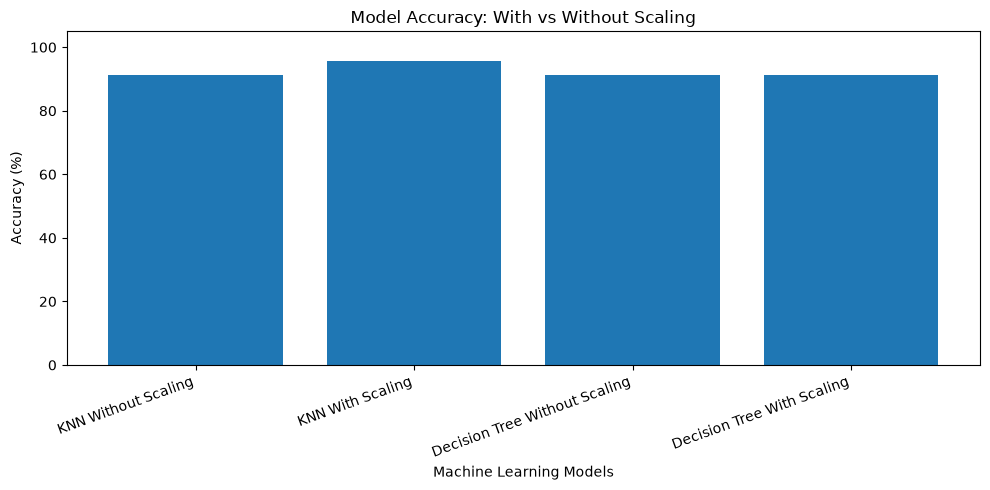

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    results['Model'],
    results['Accuracy (%)']
)

plt.title("Model Accuracy: With vs Without Scaling")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")

plt.xticks(rotation=20, ha='right')
plt.ylim(0, 105)

plt.tight_layout()
plt.show()

In [17]:
print("\n========== FINAL RESULTS ==========")

print(
    f"KNN without scaling: "
    f"{accuracy_without:.2f}"
)

print(
    f"KNN with scaling: "
    f"{accuracy_with:.2f}"
)

print(
    f"Decision Tree without scaling: "
    f"{tree_accuracy_without:.2f}"
)

print(
    f"Decision Tree with scaling: "
    f"{tree_accuracy_with:.2f}"
)

print("\n========== CONCLUSION ==========")

if accuracy_with > accuracy_without:
    print("KNN performs better with scaling.")
elif accuracy_with < accuracy_without:
    print("KNN performs better without scaling.")
else:
    print("KNN accuracy is the same in both cases.")

if np.isclose(tree_accuracy_without, tree_accuracy_with):
    print("Decision Tree accuracy remains the same.")
else:
    print("Decision Tree accuracy changed slightly.")



========== FINAL RESULTS ==========
KNN without scaling: 0.91
KNN with scaling: 0.96
Decision Tree without scaling: 0.91
Decision Tree with scaling: 0.91

========== CONCLUSION ==========
KNN performs better with scaling.
Decision Tree accuracy remains the same.
